In [2]:
# """
# Vorbereitung

# 1) mit Excel Station finden, die nahe liegt  C:\Users\CasparGross\Documents\Wetterdaten für Rasmus
# 2) Wetterdaten herungerladen:
# https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/hourly/solar/
# - Solar und air_temperature

# step 1) erstmal Dateien extrahieren
# step 2) manuell in VS txt-format in csv umwandeln (einfach mit rechtsklick + rename)

# 3) Input Dateien in nächster Zeile auswählen/angeben

# 4) Metadaten in den CSV-Dateien anpassen (aus letzte Zelle) !!! hier sehr aufpassen, dass man richtige Metadaten übernimmt!!!


# Anmerkungen zu dfs:

# """


In [2]:
# hier Koordinaten von zu untersuchendem Standort eintragen:
long_kraftwerk, lat_kraftwerk = 13.4050, 52.5200  # Berlin



# # welches Jahr soll gefiltert werden?

# 2025
year = "20251231"



# #  könnte man schon hier als Input nehmen:
# #  start = pd.Timestamp('2025-01-01 00:00')
# # ende = pd.Timestamp('2025-12-31 23:50')


# # 2024
# year = "20241231"


# # 2004
# year = "20041231"

In [9]:
import pandas as pd
import numpy as np
name_stations_excel = r"C:\Users\CasparGross\Documents\Wetterdaten für Rasmus\Stationen_1h_incl_2025.csv"

# CSV-Datei laden
stationen_1h_meta = pd.read_csv(name_stations_excel,sep=';',decimal=',', skiprows=2)
stationen_1h_meta



indicees_= np.array([i for i in range(len(stationen_1h_meta)-1) if  stationen_1h_meta[year][i] == 1])
indicees_
#stationen_mit_daten = stationen_1h_meta(indicees_)
# stationen_mit_daten

# hier einmal den df für 1h erstellen, indem wir die Einträge der vollen Stunde übernehmen.
stationen_mit_daten = stationen_1h_meta.iloc[indicees_].reset_index(drop=True)  
stationen_mit_daten


# real_headers = stationen_1h_meta
# real_headers

,ID,Start,Ende,NR,lat,long,Ort,Bundesland,Unnamed: 8,Ende.1,20251231,20241231,20041231,Unnamed: 13
0,183.0,19810101.0,20251231.0,42.0,54.6791,13.4344,Arkona,Mecklenburg-Vorpommern,NaN,NaN,1.0,1.0,1.0,NaN
1,662.0,19580101.0,20251231.0,81.0,52.2915,10.4464,Braunschweig,Niedersachsen,NaN,NaN,1.0,1.0,1.0,NaN
2,691.0,20090101.0,20251231.0,4.0,53.0451,8.7981,Bremen,Bremen,NaN,NaN,1.0,1.0,0.0,NaN
3,853.0,19810101.0,20251231.0,416.0,50.7913,12.8720,Chemnitz,Sachsen,NaN,NaN,1.0,1.0,1.0,NaN
4,867.0,20210101.0,20251231.0,344.0,50.3066,10.9679,Lautertal-Oberlauter,Bayern,NaN,NaN,1.0,1.0,0.0,NaN
5,1048.0,19960901.0,20251231.0,228.0,51.1278,13.7543,Dresden-Klotzsche,Sachsen,NaN,NaN,1.0,1.0,1.0,NaN
6,1346.0,20230101.0,20251231.0,1486.0,47.8748,8.0038,Feldberg/Schwarzwald,Baden-Württemberg,NaN,NaN,1.0,1.0,0.0,NaN
7,1358.0,19580101.0,20251231.0,1213.0,50.4283,12.9536,Fichtelberg,Sachsen,NaN,NaN,1.0,1.0,1.0,NaN
8,1639.0,20240101.0,20251231.0,203.0,50.6017,8.6439,Gießen/Wettenberg,Hessen,NaN,NaN,1.0,0.0,0.0,NaN
9,1684.0,20010101.0,20251231.0,239.0,51.1621,14.9506,Görlitz,Sachsen,NaN,NaN,1.0,1.0,1.0,NaN


In [10]:
stationen_mit_daten["lat"]

0     54.6791
1     52.2915
2     53.0451
3     50.7913
4     50.3066
5     51.1278
6     47.8748
7     50.4283
8     50.6017
9     51.1621
10    53.6332
11    47.8009
12    47.6952
13    51.3932
14    52.2085
15    53.7123
16    49.5030
17    52.3812
18    54.1803
19    49.2128
20    54.3279
21    54.5275
22    52.8911
23    48.8281
24    49.7479
25    53.7445
26    48.4024
27    49.7704
28    50.7313
29    47.4210
30    48.5451
31    49.5063
32    51.8664
33    51.4458
34    49.3910
35    50.7983
Name: lat, dtype: float64

In [11]:

from pyproj import Transformer
from geographiclib.geodesic import Geodesic
import math


# def geodesic_distance_m(lat1, lon1, lat2, lon2):
#     res = Geodesic.WGS84.Inverse(lat1, lon1, lat2, lon2)
#     return res['s12']  # in meter

# d = geodesic_distance_m(52.5200, 13.4050, 48.1371, 11.5754)

def abstand_berechnen(stationen_mit_daten):
    # WGS84 (lon, lat) -> ETRS89 / UTM zone 33N (E,N in Metern)
    # transformer = Transformer.from_crs("EPSG:4326", "EPSG:25833", always_xy=True)
    
    # E       = stationen_mit_daten["lat"]
    # N       = stationen_mit_daten["lat"]
    # Dist    = stationen_mit_daten["lat"]

    # long_kraftwerk_m, lat_kraftwerk_m = transformer.transform(long_kraftwerk,lat_kraftwerk)
    # x = (long_kraftwerk_m, lat_kraftwerk_m)
    # print(x)

    # for i in range(len(stationen_mit_daten[year])-1):
    #     lat = float(stationen_mit_daten["lat"][i])
    #     long  = float(stationen_mit_daten["long"][i])
    #     # print(lat,long)
    #     E[i], N[i] = transformer.transform(long, lat)
    #     Dist[i].replace( math.dist(x,(E[i], N[i]))  )
    
    # return(Dist)
    

    Dist    = stationen_mit_daten["lat"]
    for i in range(len(stationen_mit_daten[year])):
        lat = float(stationen_mit_daten["lat"][i])
        long  = float(stationen_mit_daten["long"][i])
        #print(lat,long)
        results = Geodesic.WGS84.Inverse(lat, long, lat_kraftwerk, long_kraftwerk)
        Dist[i] = results['s12']  # in meter
        
        print(Dist[i] )
    return(Dist)



Dist = abstand_berechnen(stationen_mit_daten)

Dist

# stationen_mit_daten["Ort"]
 

240310.27939888285
202932.9279303227
316232.02738826745
195839.92397128907
298942.7953811659
156762.17781434715
644366.2315386399
234819.4723121881
393024.6212617159
184853.46877743985
260318.93474474188
552009.4358023672
617402.1324800586
246788.87143045472
59668.60516155944
439038.5943631618
373920.6179704441
27958.979186431738
204733.57440011075
575737.6468629384
377217.42283141863
339517.2292284715
120530.19092712163
506786.7291391339
563663.8260907677
143351.9459948103
473824.4569562969
389483.03274730186
200452.6095805428
593043.912352282
442180.0294646791
477387.8645444611
291850.2602051432
438438.8751624174
351757.1990217432
545159.7899241154


C:\Users\CasparGross\AppData\Local\Temp\ipykernel_32172\3277959192.py:40: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Dist[i] = results['s12']  # in meter
C:\Users\CasparGross\AppData\Local\Temp\ipykernel_32172\3277959192.py:40: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Dist[i] = results['s12']  # in meter
C:\Users\CasparGross\AppData\Local\Temp\ipykernel_32172\3277959192.py:40: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Dist[

0     240310.279399
1     202932.927930
2     316232.027388
3     195839.923971
4     298942.795381
5     156762.177814
6     644366.231539
7     234819.472312
8     393024.621262
9     184853.468777
10    260318.934745
11    552009.435802
12    617402.132480
13    246788.871430
14     59668.605162
15    439038.594363
16    373920.617970
17     27958.979186
18    204733.574400
19    575737.646863
20    377217.422831
21    339517.229228
22    120530.190927
23    506786.729139
24    563663.826091
25    143351.945995
26    473824.456956
27    389483.032747
28    200452.609581
29    593043.912352
30    442180.029465
31    477387.864544
32    291850.260205
33    438438.875162
34    351757.199022
35    545159.789924
Name: lat, dtype: float64

In [26]:

print(stationen_mit_daten["Ort"][Dist.idxmin()])
stationen_mit_daten.iloc[[Dist.idxmin()]]

Potsdam


,ID,Start,Ende,NR,lat,long,Ort,Bundesland,Unnamed: 8,Ende.1,20251231,20241231,20041231,Unnamed: 13
17,3987.0,19451231.0,20251231.0,81.0,27958.979186,13.0622,Potsdam,Brandenburg,NaN,NaN,1.0,1.0,1.0,NaN


AttributeError: 'numpy.float64' object has no attribute 'plot'

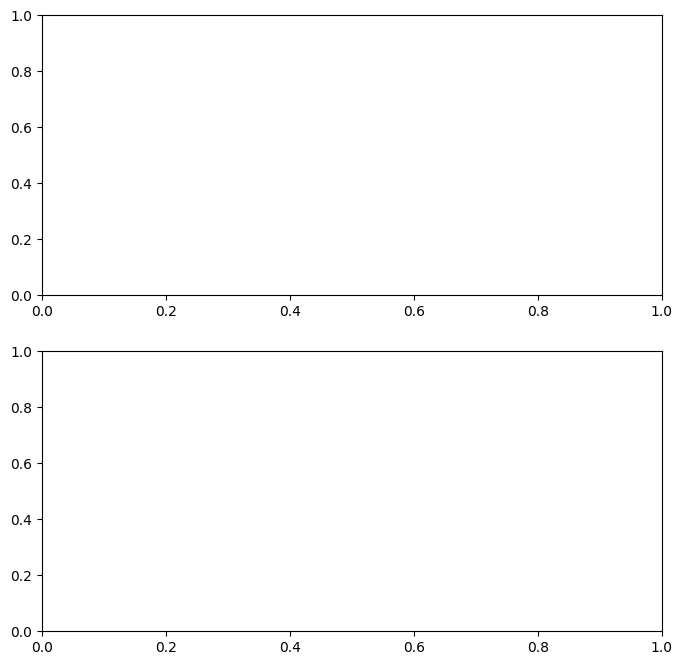

In [ ]:
import matplotlib.pyplot as plt


x=stationen_mit_daten["Ort"]
y=Dist[1].transpose

fig, axes = plt.subplots(figsize=(8,8),nrows=2, ncols=1)
ax1=plt.subplot(2,1,1)

Dist[1].plot(ax=axes[0,1], kind='bar', grid=True)

# plt.plot(x,y)

# #ax2=plt.subplot(2,2,2)
# df["b"].plot(ax=axes[0,1], kind='bar', grid=True)
# df["c"].plot(ax=axes[1,0], kind='bar', grid=True)
# df["d"].plot(ax=axes[1,1], kind='bar', grid=True)

# ax1.grid(True)
# ax1.set_ylabel('Test')
# ax1.set_xlabel('Test2')

#ax2.set_ylabel('Test')

In [ ]:

import pandas as pd
import numpy as np

# Inputs und Auswahl des Jahres
name = 'produkt_st_stunde_19580101_20251231_00662_Braunschweig.csv'
name_tamb = 'produkt_tu_stunde_20240805_20260205_00662_Braunschweig.csv'


stationsID = 'station_00662_Braunschweig'
timestep = '1h_'

# # welches Jahr soll gefiltert werden?
# 2025
start = pd.Timestamp('2025-01-01 00:00')
ende = pd.Timestamp('2025-12-31 23:50')



# # # welches Jahr soll gefiltert werden?
# # 2024
# start = pd.Timestamp('2024-01-01 00:00')
# ende = pd.Timestamp('2024-12-31 23:50')

# # 2004
# start = pd.Timestamp('2004-01-01 00:00')
# ende = pd.Timestamp('2004-12-31 23:50')


# CSV-Datei laden
df = pd.read_csv(name,sep=';')
df_Tamb = pd.read_csv(name_tamb,sep=';')
df_Tamb



,STATIONS_ID,MESS_DATUM,QN_9,TT_TU,RF_TU,eor
0,662,2024080500,3,14.1,80.0,eor
1,662,2024080501,3,13.1,88.0,eor
2,662,2024080502,3,13.7,86.0,eor
3,662,2024080503,3,14.1,86.0,eor
4,662,2024080504,3,14.4,84.0,eor
...,...,...,...,...,...,...
13195,662,2026020519,1,-2.1,95.0,eor
13196,662,2026020520,1,-1.9,95.0,eor
13197,662,2026020521,1,-1.6,94.0,eor
13198,662,2026020522,1,-1.2,94.0,eor


In [ ]:
#achtung! name muss noch im cache sein!

# name_new_1 = name.replace('.csv', '_2024_1h_1_for_pv_syst.csv')
from ntpath import join


start_string = start.strftime("%Y-%m-%d")
ende_string = ende.strftime("%Y-%m-%d") 

csv_eding = 'for_pv_syst.csv'
name_new_1 = ''.join([stationsID,"_",start_string,"_",ende_string,"_",timestep,'_1_',csv_eding])

# nur ausführen wenn Datei ready ist, sonst wird bestehende Datei überschrieben 
df_neu_relevant.to_csv(name_new_1, sep=';', index=False, header=['Year','Month','Day','Hour','Minute','GHI','DHI','Tamb'])


#   diese Header händisch hinzufügen

#Meteo hourly data;;;;;;;
#Description of Data Set e.g. DWD DataBase;;;;;;;
# GHI. DHI and Temp are retrieved. Set Time Zone to 0. since time stamp is in UTC!;;;;;;;
#Site; 00662_Braunschweig;;;;;;;
#Country; germany;;;;;;;
#Data Source; DWD_station_00662_Braunschweig;;;;;;;
#Time step; 1h;;;;;;;
#Year; 2024;;;;;;;
#Latitude; 52.2915;;;;;;;
#Longitude; 10.4464;;;;;;;
#Altitude; 81.44;;;;;;;
#Time Zone; 1  ;;;;;;;
#Time reference;UT;;;;;;
#Hour Shift;-1;;;;;;
#Time Shift;0;;;;;;

# --> muss aber individuell je nach Metadaten angepasst werden (könnte man aber in Zukunft automatisieren)

# Zielformat
# Year;Month;Day;Hour;Minute;GHI;Tamb;
# ;;;;;W/m2;deg.C;

In [ ]:
"""
ToDo:

# location checken

# Simulieren mit Lima

# in Zukunft Interpolieren, wenn Werte fehlen!!! -> hat jetzt durch Zufall auch ohne funktioniert, aber kann man sich nicht 100%ig drauf verlassen

# Wetterstationen filtern später


Index of /climate_environment/CDC/observations_germany/climate/hourly/solar/
https://www.pvsyst.com/help/meteo-database/notes-on-meteo/meteonote7-time-shift-in-meteo-files.html#time-shift-correction-when-importing-data 


"""

'\nToDo:\n\n# location checken\n\n# Simulieren mit Lima\n\n# in Zukunft Interpolieren, wenn Werte fehlen!!! -> hat jetzt durch Zufall auch ohne funktioniert, aber kann man sich nicht 100%ig drauf verlassen\n\n# Wetterstationen filtern später\n\n\nEs reicht am Anfang #Time Reference; 1  zu ergänzen --> das müsste für PV-Syst dann klar stellen, dass es selbst den Shift von UTF 1 zu local time macht\n\nhttps://www.pvsyst.com/help/meteo-database/notes-on-meteo/meteonote7-time-shift-in-meteo-files.html#time-shift-correction-when-importing-data \nIf there is a time shift varying along the year:\n\nWith the general ASCII importing tool, consider using the DST correction (option "Summer Time > Apply").\nOtherwise there is no practical way, except modifying the dates directly in the source file.\nIf the file is written in UT (Universal Time):\n\nWith the general ASCII importing tool, check the box "Universal time".\nWith PVsyst standard format, you can add a line #Time Reference with the value 